## 지난 수업 복습

### REINFORCE와 Actor-Critic
1. REINFORCE
    - 에피소드 전체를 모은 뒤 Monte Carlo return 'G_t'를 계산하여 정책을 업데이트
    - 정책 경사의 기본 개념이 명료함. 분산 크고 에피소드 종료까지 기다려야 함

2. Actor-Critic 정책(Actor)과 가치 함수(Critic)를 동시에 학습하여, 더 안정적이고 효율적인 학습 가능
    - Actor는 정책 `π(a|s)`를 학습하고, Critice은 상태 가치 함수 `V(s)`를 학습
    - TD 목표 : `y_t = r_t + γ(1-d_t)V(s_{t+1})` 구함
    - Advantage 
        - 내가 선택한 행동이 평소 기대했던 것보다 얼마나 좋은지 나타냄
        - V(s): 현재 상태에서 앞으로 얼마나 많은 보상을 받을 것으로 기대되는지 나타냄
        - Advantage A(s, a): 현재 상태에서 행동이 평균적인 기대보다 얼마나 좋은지 나타냄
            - `A_t ≈ y_t − V(s_t)`
            - 값이 양수: 그 행동의 선택 확룰이 높아짐
            - 값이 음수: 그 행동의 선택 확률이 낮아짐
            ```
                평소 예상 점수는 70점이었는데, 실제로 90점을 받음
                    Advantage = 90 - 70 = +20
                평소 예상 점수는 70점이었는데, 실제로 50점을 받음
                    Advantage = 50 - 70 = -20
            ```
            - Advantage를 주면 무엇이 달라질까? 
                - 내가 움직여야 할 방향이 커져 학습을 할 때 더 빠르게 정책이 개선됨
                - 없어도 학습은 가능하지만, Advantage를 사용하면 정책 개선이 더 빠르게 이루어짐
    - Actor 손실 `L_actor = −log π(aₜ|sₜ) · stop_gradient(Aₜ)`
    - Critic 손실 `L_critic = (V(sₜ) − yₜ)²`
    - 손실을 구하는 이유:
        - Actor 손실: 정책을 개선하기 위해, Advantage가 양수일 때 행동 선택 확률을 높이고, 음수일 때 낮춤
        - Critic 손실: 상태 가치 함수가 TD 목표에 맞게 정확히 예측하도록 학습
    

___

# **1. A2C**
- A2C(Advantage Actor-Critic)는 정책(Actor)과 가치 함수(Critic)를 함께 학습하면서, Advantage를 이용해 정책의 방향을 정하는 Actor-Critic 계열 알고리즘이다.
- A2C는 n개의 환경이 일정한 길이 T만큼 경험을 수집한 뒤, 그 경험을 합쳐서 한 번에 신경망을 업데이트함

### **1-1. A2C의 배경**
- 단일 환경에서 연속으로 수집한 경험은 비슷한 장면이 반복
- 환경 여러개에서 서로 다른 상태를 경험하면 학습 배치가 다양해져 학습이 안정적이고 효율적으로 이루어짐
- 한 스텝만 보지 않고 n-step return을 사용해 조금 더 먼 미래의 보상까지 고려하여 정책을 업데이트함
- 동기시이므로 모든 환경이 모인 뒤 갱신해 업데이트 절차를 이해/재현하기 쉬움
    - 동기식으로 모든 환경이 모인 뒤 한 번에 업데이트함

학생 한명이 게임을 100번 하는게 아니라, 4명의 학생이 25번씩 게임을 해서 100번의 경험을 모으는것과 비슷 -> 이게 더 쉽지않은가? 이걸 나눠서 하고 합쳐서 사용방법에 대한 메뉴얼을 쓰는것이 동기식이고(차례 차례 이뤄지니까), 더 도움을 받지 않을까? 하는것 (점진적으로 좀 더 똑똑해지지 않을까?)

![A2C](./images/ref/05_01.png)

### **1-3. 수식들**

#### 1-3-1. 한 스텝 TD
- 1-step TD 목표값에서 현재 상태의 가치 V(sₜ)를 빼면 TD 오차구하는거
- 현재 보상과 다음 상태의 예상 가치를 더한 값으로, 한 스텝 뒤의 총 보상을 추정한 것
- 1 = 하나의 스텝

$
\boxed{G_t^{(1)}=r_t+\gamma V(s_{t+1})}
$


#### 1-3-2. n-step Return
- n개의 스텝에서 받은 보상과 마지막 상태의 예상 가치를 합한 값
- 1-step보다 더 먼 미래의 보상까지 고려함

$
\boxed{G_t^{(n)}=r_t+\gamma r_{t+1}+\cdots+\gamma^{n-1}r_{t+n-1}+\gamma^n V(s_{t+n})}
$


#### 1-3-3. Advantage
- n-step Return에서 현재 상태의 예상 가치를 뺀 값
- 양수면 예상보다 좋은 행동, 음수면 예상보다 나쁜 행동

$
\boxed{A_t=G_t^{(n)}-V(s_t)}
$


#### 1-3-4. 전체 손실 
- Actor Loss: Advantage를 이용해 행동 선택 확률을 학습
- Critic Loss: 예측 가치와 목표값의 차이를 줄이도록 학습
- Entropy: 특정 행동에만 치우치지 않도록 탐색을 장려

$
\boxed{L=-\mathbb E[\log\pi(a_t|s_t)\,\mathrm{stopgrad}(A_t)]+c_v\mathbb E[(V(s_t)-G_t^{(n)})^2]-c_e\mathbb E[H(\pi(\cdot|s_t))]}
$

> n-step의 n은 신경망의 층 수가 아니라, 앞으로 관찰한 보상의 스텝수임!!

### **1-4. 예시 문제 (Advantage 계산)**

#### 1-4-1. 문제 설정
```
r_0 = 1     : 첫 번째 행동 후 받은 보상
r_1 = 1     : 두 번째 행동 후 받은 보상
r_2 = 1     : 세 번째 행동 후 받은 보상
γ = 0.9     : 미래 보상에 적용하는 할인율
V(s_3) = 5  : 세번째 행동 후 상태에서 앞으로 받을 것으로 예상되는 보상
V(s_0) = 4  : 첫 번째 행동 후 상태에서 앞으로 받을 것으로 예상되는 보상
```

#### 1-4-2. 문제 풀이
1. AI가 3번의 행동으로 실제 받은 보상의 합계는 얼마일까?
    - r_0 + r_1 + r_2 = 1 + 1 + 1 = 3
2. 미래 보상에 할인율을 적용해 계산한 3-step Return은 얼마일까?
    - G_0 = r_0 + γ * r_1 + γ^2 * r_2 + γ^3 * V(s_3)
    - = 1 + 0.9 * 1 + 0.9^2 * 1 + 0.9^3 * 5
    - = 1 + 0.9 + 0.81 + 3.645
    - = 6.355
    - 이 6.355는 실제 받은 보상(3점)과 앞으로 받을 것으로 예상되는 보상(3번 행동한 이후 매라 예상 가치)을 모두 고려한 값이다.
3. 처음 예상했던 가치와 비교한 Advantage는 얼마일까?
    - Advantage = 처음 예상했던 가치와 새롭게 계산한 목표 가치의 차이임
        - Critic은 현재 상태의 가치를 4점이라 예상함
        - 3번 행동한 경험과 미래 예상 가치를 이용해 계산한 값은 6.355임
        - 그래서 6.355 - 4를 했더니 2.355가 나옴 `A_0 = G_0 - V(s_0)`
4. 위 결과처럼 Advantage가 양수라는 것은 어떤 의미?
    - 실제로 받은 보상과 미래 예상 보상을 합한 값이 처음 예상했던 가치보다 크다는 의미임
    - 즉, Critic이 처음 예상했던 가치보다 더 좋은 결과가 나왔다는 뜻임
    - Actor는 처음 상태 s0에서 선택했던 행동의 확률을 높이는 방향으로 학습하게 됨

![문제풀이 이미지](./images/ref/05_02.png)

### **1-4-3. 코드로 풀기**

In [4]:
gamma = 0.9
rewards = [1.0, 1.0, 1.0]
bootstrap_value = 5.0
running = bootstrap_value
for r in reversed(rewards):
    running = r + gamma * running
print('3-step return: ', round(running, 3))
print('advantage: ', round(running - 4.0, 3))

3-step return:  6.355
advantage:  2.355


### **1-4-4. 신경망으로 Advantage 계산하기**

In [5]:
import random, time, math, copy
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.distributions import Categorical, Normal
import gymnasium as gym

In [6]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [7]:
# seed 설정 함수
def set_seed(seed=2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [8]:
class DiscreteActorCritic(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2, hidden=128):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh()
        )
        self.actor = nn.Linear(hidden, n_actions)
        self.critic = nn.Linear(hidden, 1)

    def forward(self, states):
        features = self.body(states)
        logits = self.actor(features)
        values = self.critic(features).squeeze(-1)
        return logits, values

net_test = DiscreteActorCritic().to(DEVICE)
logits, values = net_test(torch.zeros(4, 4, device=DEVICE))
print('logits:', logits.shape, 'values:', values.shape)

logits: torch.Size([4, 2]) values: torch.Size([4])


### **1-4-5. A2C 학습 과정 구현 실습**
1. 환경 N개 만들고 상태 모으기
2. T번 반복하면서 같은 정책으로 각 환경의 행동 선택
3. 보상, 종료 여부, 가치, 행동 로그확률, 엔트로피 저장하기
4. 각 환경 종료되면 다음 에피소드로 리셋. 단 종료 전 마지막 관측에서 계산한 부트스트랩 가치를 보존할 것
5. 역순으로 n-step Return 계산하기
6. Actor / Critic / Entropy 손실 합산하고 optimizer.step() 호출해서 기울기 수정
> 위 내용을 넣은 training loop 작성하기

In [9]:
# 환경 설정하는 함수 따로 뺀거임
def make_envs(n=4, name="CartPole-v1", seed=2026):
    envs = [gym.make(name) for _ in range(n)]
    states = []
    for i, env in enumerate(envs):
        env.action_space.seed(seed + i)
        state, _ = env.reset(seed=seed + i)
        states.append(state)
    return envs, np.asanyarray(states, dtype=np.float32)

In [10]:
# 4개 게임을 각각 5스텝씩 실행하고, 총 20개의 경험을 모아 한 번 학습하는 과정을 300회 반복
# 300 * 4 * 5 = 6000(총 환경 스텝 수 = 총 경험 수)
def train_a2c(
        updates=3000, n_envs=4, rollout_steps=5, seed=2026, gamma=0.99, lr=7e-4, value_coef=0.5, entropy_coef=0.01, print_every=50
    ):

    set_seed(seed)

    # envs = [환경0, 환경1, 환경2, 환경3]
    # states = [환경0의 초기 상태, 환경1의 초기 상태, 환경2의 초기 상태, 환경3의 초기 상태]
    # 상태: 카트위치, 속도, 막대기의 기울기, 각 속도 
    envs, states = make_envs(n_envs, seed=seed)
    model = DiscreteActorCritic().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # 각 환경에서 현재 진행중인 에피소드의 누적보상 저장
    episode_scores = np.zeros(n_envs, dtype=np.float64)
    completed = []
    history = []

    try:
        for update in range(1, updates + 1):
            # logps: 실제 선택한 행동의 로그 확률
            # vals: Critic이 예측한 현재 상태 가치
            # bootstraps: 다음 상태에서의 예상 가치
            # boundaries: 에피소드 종료 여부
            logps, vals, rewards, bootstraps = [], [], [], []
            boundaries, entropies = [], []

            # rollout_steps 동안 각 환경에서 행동을 선택하고, 그 결과를 기록
            for t in range(rollout_steps):
                x = torch.as_tensor(states, dtype=torch.float32, device=DEVICE)
                logits, value = model(x)
                dist = Categorical(logits=logits)
                actions = dist.sample()
                logps.append(dist.log_prob(actions))
                vals.append(value)
                entropies.append(dist.entropy())


                next_states, rs, bs, ends = [], [], [], []
                for i, env in enumerate(envs):
                    # ns: 다음 상태 (next state)
                    ns, r, terminated, truncated, _ = env.step(int(actions[i].item()))
                    episode_scores[i] += float(r)
                    # 두 종료 조건 중 하나라도 참이면 현재 에피소드가 끝났다라고 판단
                    boundary = bool(terminated or truncated)
                    # rs: 즉시 보상 (reward)
                    rs.append(float(r))
                    # ends: 에피소드 경계 여부
                    ends.append(boundary)
                    # bs: 종료 직전 다음 상태와 실제 종료 여부 (terminated)
                    # ns를 저장하는 이유는 truncated=True일 때 다음 상태 가치를 이용해 Bootstrap을 계산하기 위함
                    bs.append((ns, bool(terminated)))
                    if boundary:
                        # 환경 종료 시
                        # 1. 종료된 에피소드의 최종 보상 저장
                        # 2. 해당 환경의 누적 보상을 0으로 초기화
                        # 3. env.reset()으로 새로운 에피소드 시작
                        completed.append(float(episode_scores[i]))
                        episode_scores[i] = 0.0
                        ns, _ = env.reset()
                        # ns는 종료되지 않았다면 행동 후의 다음 상태, 종료되었다면 새로 초기화한 상태가 저장

                    next_states.append(ns)
                
                # 그럼 여기서 말하는 Bootstrap이란?
                # 아직 경험하진 않았지만, 경험하지 않은 미래의 보상을 Critic을 이용해 예측
                # 예를 들어 5스텝까지 진행했지만 게임 끝나지 않았다면 5스텝 이후 받을 보상은 아직 알 수 없음
                # 이때 Critic이 예측한 다음 상태 가치를 10점이라 예측했다면 그 값을 미래 보상의 추정치로 사용하는 것
                # bs: [(환경 0의 다음 상태, False), (환경 1의 다음 상태, True), ...]
                bootstrap_x = torch.as_tensor(
                    np.asanyarray([item[0] for item in bs], dtype=np.float32), device=DEVICE
                )

                with torch.no_grad():
                    _, bootstrap_values = model(bootstrap_x)
                    """
                        bootstrap_values = [12.0, 8.0, 15.0, 20.0]
                        terminated = True = 1
                        terminated = False = 0

                        환경 0, 다음 상태 가치 12.0, terminated = False 라면 최종 Bootstrap 값은 12.0
                        환경 1, 다음 상태 가치 8.0, terminated = True 라면 최종 Bootstrap 값은 0.0
                        환경 2, 다음 상태 가치 15.0, terminated = False 라면 최종 Bootstrap 값은 15.0
                        환경 3, 다음 상태 가치 20.0, terminated = False 라면 최종 Bootstrap 값은 20.0
                    """
                    true_terminal = torch.tensor(
                        [float(item[1]) for item in bs], device=DEVICE
                    )
                    bootstrap_values = bootstrap_values * (1.0 - true_terminal)

                rewards.append(torch.tensor(rs, dtype=torch.float32, device=DEVICE))
                bootstraps.append(bootstrap_values)
                boundaries.append(torch.tensor(ends, dtype=torch.bool, device=DEVICE))
                states = np.asanyarray(next_states, dtype=np.float32)

            # 5스텝 동안 얻은 보상과 미래 예상 가치를 역순으로 합산
            # why? 역순으로 계산할까?
            # 마지막 스템의 미래 가치를 먼저 알아야 이전 스텝의 Return을 계산할 수 있으니까
            """
                rewards = [1, 1, 1]
                gamma = 0.9
                next_value = 5

                역순 계산
                마지막 Bootstrap 값은 next_value = 5로, 5가 됨
                
                그럼 t = 2일 때 계산은 1 + 0.9 * 5 하면 됨 = 5.5
                t = 1일 때 계산은 1 + 0.9 * 5.5 = 5.95
                t = 0일 때 계산은 1 + 0.9 * 5.95 = 6.355
            """
            running = bootstraps[-1]
            targets = [None] * rollout_steps
            for t in reversed(range(rollout_steps)):
                # 왜 이렇게 했을까?
                # 환경 0이 세 번쨰 스텝에서 종료되고, 네 번째 스텝부터 새로운 게임이 시작된다면
                # 이전 게임의 Return에 새로운 게임의 보상을 섞이지 않도록 하기 위해 조건을 달아준거임!
                running = torch.where(boundaries[t], bootstraps[t], running)
                running = rewards[t] + gamma * running
                targets[t] = running

            # 이제 다 합쳐주면 됨
            target_t = torch.stack(targets).detach()
            value_t = torch.stack(vals)
            logp_t = torch.stack(logps)
            entropy_t = torch.stack(entropies)
            advantage = target_t - value_t

            # loss 계산 및 학습
            actor_loss = -(logp_t * advantage.detach()).mean()
            critic_loss = advantage.square().mean()
            entropy_bonus = entropy_t.mean()
            loss = actor_loss + value_coef * critic_loss - entropy_coef * entropy_bonus

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 0.5)
            optimizer.step()

            # 학습 로그 출력
            recent = float(np.mean(completed[-20:])) if completed else np.nan
            history.append({'update': update, 'episodes_done': len(completed),
                            'recent20_reward': recent, 'loss': float(loss.item())})
            if update % print_every == 0:
                print(
                    f'A2C update {update:4d}/{updates} | 종료 에피소드 {len(completed):4d} '
                    f'| 최근20 평균 {recent:7.2f}'
                )

    finally:
        for env in envs:
            env.close()

    return model, pd.DataFrame(history), completed

In [11]:
a2c_model, a2c_hist, a2c_scores = train_a2c(updates=3000, n_envs=4, rollout_steps=5, seed=2026, print_every=50)

A2C update   50/3000 | 종료 에피소드   38 | 최근20 평균   25.05
A2C update  100/3000 | 종료 에피소드   76 | 최근20 평균   30.90
A2C update  150/3000 | 종료 에피소드  111 | 최근20 평균   28.55
A2C update  200/3000 | 종료 에피소드  147 | 최근20 평균   27.40
A2C update  250/3000 | 종료 에피소드  182 | 최근20 평균   29.45
A2C update  300/3000 | 종료 에피소드  208 | 최근20 평균   39.95
A2C update  350/3000 | 종료 에피소드  240 | 최근20 평균   30.65
A2C update  400/3000 | 종료 에피소드  267 | 최근20 평균   34.75
A2C update  450/3000 | 종료 에피소드  292 | 최근20 평균   41.65
A2C update  500/3000 | 종료 에피소드  314 | 최근20 평균   45.35
A2C update  550/3000 | 종료 에피소드  334 | 최근20 평균   49.10
A2C update  600/3000 | 종료 에피소드  357 | 최근20 평균   47.00
A2C update  650/3000 | 종료 에피소드  385 | 최근20 평균   32.75
A2C update  700/3000 | 종료 에피소드  405 | 최근20 평균   43.35
A2C update  750/3000 | 종료 에피소드  422 | 최근20 평균   62.55
A2C update  800/3000 | 종료 에피소드  438 | 최근20 평균   59.95
A2C update  850/3000 | 종료 에피소드  463 | 최근20 평균   38.25
A2C update  900/3000 | 종료 에피소드  487 | 최근20 평균   41.35
A2C update  950/3000 | 종료 에피

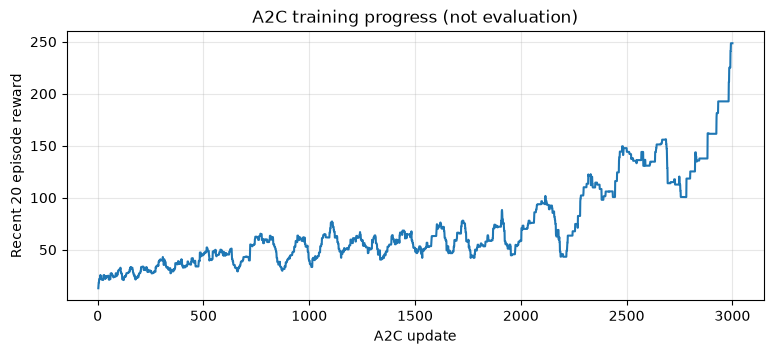

In [12]:
plt.figure(figsize=(9, 3.5))
plt.plot(a2c_hist['update'], a2c_hist['recent20_reward'])
plt.xlabel('A2C update')
plt.ylabel('Recent 20 episode reward')
plt.title('A2C training progress (not evaluation)')
plt.grid(alpha=0.3)
plt.show()

이건 강사님 결과

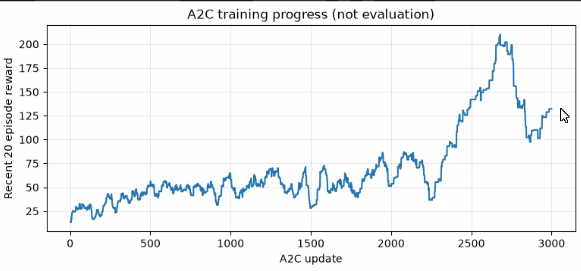

___
# **2. A3C**
- A3C(Asynchronous Advantage Actor-Critic)
- A2C는 Worker들이 데이터를 수집한 뒤 모두 모일때까지 기다림 > 느린 Worker가 있으면 전체 업데이트가 늦어짐
- A3C는 각 Worker가 독립적으로 환경을 탐험하고, 계산한 기울기를 공유 모델에 비동기적으로 반영함

```
worker1 : 환경 1 > 경험 > Local Gradient
worker2 : 환경 2 > 경험 > Local Gradient
worker3 : 환경 3 > 경험 > Local Gradient
.
.
.
이걸 다 모아서
Global Actor-Critic 파라미터에 적용
```

- Global Network: 여러 Worker가 공동으로 개선하는 모델
- Local Network: 각 Worker가 행동을 선택하고 기울기를 계싼할 떄 쓰는 복사본
- 비동기: 모든 Worker가 한 번에 끝나기를 기다리지 않음

n-step return 식

$R_t=\sum_{k=0}^{n-1}\gamma^k r_{t+k}+\gamma^n V(s_{t+n})$

> 주의해야 할 점: 비동기라는 말이 무조건 빠르다는 뜻 아님. 하지만 CPU 코우서, 공유 파라미터 경쟁, 프로세스 생성 비용에 영향을 받을 수 있음

```
예를 들어 보상이 [1, 1, 1]이고 γ=0.9라면

3스텝 후 가치가 2일 때 
R = 1 + 0.9 + 0.81 + 0.9^3 * 2 
= 1 + 0.9 + 0.81 + 1.458 
= 4.168

근데 가치가 3이라면 Advantage는 R - V(s) = 4.168 - 3 = 1.168
= 4.168 - 3
= 1.168
```

In [13]:
def nstep_return(rewards, bootstrap, gamma=0.9):
    R = bootstrap
    for r in reversed(rewards):
        R = r + gamma * R
    return R

print("3-step return:", nstep_return([1, 1, 1], 2))
print("Advantage:", nstep_return([1, 1, 1], 2) - 3)

3-step return: 4.168
Advantage: 1.1680000000000001


In [ ]:
# Actor-Critic 신경망
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        # 공통 신경망: 상태값 4개를 입력받아 64개의 특징값으로 변환
        self.body = nn.Sequential(
            nn.Linear(4, 64),
            nn.ReLU()
        )
        self.actor = nn.Linear(64, 2)
        self.critic = nn.Linear(64, 1)

    def forward(self, x):
        h = self.body(x)
        return self.actor(h), self.critic(h).squeeze(-1)

In [18]:
def worker(rank, global_net, lock, queue, episodes=300, gamma=0.99, n_steps=5):
    torch.manual_seed(100 + rank)
    random.seed(100 + rank)
    env = gym.make('CartPole-v1')
    local = Net()
    optimizer = torch.optim.SGD(global_net.parameters(), lr=0.001)
    for ep in range(episodes):
        with lock:
            local.load_state_dict(global_net.state_dict())
        obs, _ = env.reset(seed = 1000 + rank * 100 + ep)
        done = False
        score = 0
        while not done:
            logps = []
            values = []
            rewards = []
            entropies = []
            for _ in range(n_steps):
                x = torch.tensor(obs, dtype=torch.float32)
                logits, v = local(x)
                dist = Categorical(logits=logits)
                a = dist.sample()
                nxt, r, terminated, truncated, _ = env.step(a.item())
                logps.append(dist.log_prob(a))
                values.append(v)
                rewards.append(r)
                entropies.append(dist.entropy())
                score += r
                obs = nxt
                done = terminated or truncated
                # terminated or truncated 둘 중 하나가 True이면 에피소드 종료
                if done:
                    break
            
            with torch.no_grad():
                bootstrap = 0.0 if terminated else local(torch.tensor(obs, dtype=torch.float32))[1].item()
            targets = []
            R = bootstrap

            for r in reversed(rewards):
                R = r + gamma * R
                targets.insert(0, R)

            targets = torch.tensor(targets, dtype=torch.float32)
            values = torch.stack(values)
            logps = torch.stack(logps)
            advantages = targets - values
            loss = -(logps*advantages.detach()).mean() + 0.5 * advantages.square().mean() - 0.01 * torch.stack(entropies).mean()
            local.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(local.parameters(), 5)
            with lock:
                for lp, gp in zip(global_net.parameters(), local.parameters()):
                    gp.grad = lp.grad.detach().clone() if lp.grad is not None else None
                optimizer.step()
                local.load_state_dict(global_net.state_dict())
        queue.put((rank, ep+1, score))
    env.close()


In [19]:
# multiprocess이란?
# 파이썬에서 여러 프로세스를 동시에 실행하여 병렬 처리를 가능하게 하는 모듈
# 멀티코어 CPU를 활용하여 연산 속도를 높일 수 있음
# multiprocessing과 유사하지만, 더 다양한 객체를 직렬화하여 전달할 수 있음
import multiprocess as mp

![멀티프로세스와 쓰레드 차이(아래코드)](./images/ref/05_03.png)

![프로세스들 비교](./images/ref/05_04.png)

In [21]:
def main():
    # set_start_method: 프로세스를 시작하는 방식 설정
    # 새로운 파이썬 프로세스를 독립적으로 생성
    # force=True: 이미 시작 방식이 설정되어 있어도 다시 설정
    mp.set_start_method('spawn', force=True)
    global_net = Net()
    global_net.share_memory()  # 다중 프로세스에서 공유 메모리로 설정
    # Lock: 잠금장치임!
    # :: A3C에서 여러 Worker가 하나의 Global Network를 공유하는데, Worker가 동시에 GlobalNetwork 가중치를 수정못하도록 설계
    lock = mp.Lock()
    # Queue: 선입선출 자료구조 (반대는 Stack)
    # ::데이터 전달 통로로, 여러 프로세스 사이에서 데이터 주고받기 위한 자료구조임!
    queue = mp.Queue()
    workers = [mp.Process(target=worker, args=(i, global_net, lock, queue)) for i in range(2)]

    # [프로세스와 쓰레드의 차이]
    # 프로세스: 기본적으로 독립적인 메모리 공간을 가진 실행 단위
    # 스레드: 하나의 프로세스 안에서 메모리를 공유하는 실행 단위

    # 현재 A3C는 멀티프로세싱 방식으로 구현
    # Worker 프로세스 2개를 생성하여 각각 독립적으로 환경을 실행
    # Global Network의 파라미터는 공유 메모리로 관리
    # Lock은 공유 자원 접근 시 동기화에 사용
    # Queue는 Worker의 학습 기록을 메인 프로세스에 전달

    # 예시) 게임에서 점프 시 사운드를 집어넣을 때
    # :: 원래는 하나의 프로세스에서 사운드를 처리하면 사운드가 들린 후 점프 행동을 하게 됨
    # :: 하지만 동시에 이뤄지게 하고싶다고!
    # :: 멀티프로세스 환경에서는 각 프로세스가 독립적으로 실행되므로, 사운드 재생도 각 프로세스에서 처리해야 함

    # start(): 프로세스 시작 요청!
    # :: 각 프로세스는 하나의 worker가 학습이 끝날때까지 기다려주지 않고 독립적으로 실행됨
    for p in workers:
        p.start()

    # queue.get(): queue에서 데이터를 가져옴 (FIFO)
    # :: 왜 600번했을까(range) = workers 수 * 각 worker가 보내는 기록 수 = 2 * 300 = 600
    # timeout=180: 최대 180초 기다리고 데이터가 없으면 예외 발생시킴
    records = [queue.get(timeout=180) for _ in range(600)]

    for p in workers:
        # join(): 프로세스가 종료될 때까지 기다림 (최대 30초)
        p.join(timeout=30)

    for p in workers:
        # is_alive(): 프로세스가 아직 살아있는지 확인
        # terminate(): 프로세스를 강제로 종료 (join으로 기다려도 종료되지 않을 때 사용)
        if p.is_alive():
            p.terminate()

    # np.save(): numpy 배열을 파일로 저장
    np.save('a3c_scores.npy', np.array(records, dtype=float))
    torch.save(global_net.state_dict(), 'a3c_cartpole.pt')
    print('A3C finished, mean of last 10 records: ', np.mean([x[2] for x in records[-10:]]))

In [ ]:
if __name__ == "__main__":
    main()

위 코드 프로세스땜에 py파일로 돌렸는데 마지막 10개 에피소드 평균이 16.5나옴
- 5_A3C.ipynb : 수업 최종 파일 (최종 490.37)
- 5_A3C_my.ipynb : 내가 시도해본 파일 (최종 109.8)

#### 결론 먼저!
내꺼랑 강사님이랑 최종적으로 다른건 에피소드수(나는 1500, 강사님은 2000)이고,<br>
Global Network 초기화할 때 나는 별도로 seed 설정이 없는데 강사님은 `torch.manual_seed(2026)` 요거 있음<br>
이 두개 사항 적용하면 125.1 나오고, 강사님이랑 점수 차이 나는 이유는<br>
평가 방식이 다름!
- 내꺼: 마지막 10개 학습기록 평균
- 강사님꺼: Greedy 정책 평가
    - 학습 끝난 후 CartPole 환경에서 30개 에피소드 평가함
    - `logits.argmax()`로 가장 높은 확률에 행동만 선택하는거임

#### 수업최종 - 변경사항
- 학습 에피소드(Episodes) : 1,500회 → 2,000회
- N-step : 20 유지
- 학습률(Learning Rate) : 0.0003 유지
- Optimizer : Shared Adam 유지
- Worker : 2개 유지
- 모델 저장 : 최종 모델 외에 최고 성능 체크포인트 추가 저장
- 평가 : 학습 종료 후 30개 에피소드로 별도 평가
Best Checkpoint 저장 : 학습 중 400개 에피소드 기록마다 모델 성능을 평가하고, 이전보다 평균 보상이 높은 경우 해당 시점의 가중치를 a3c_best.pt로 저장함.

#### 수업최종 - 학습 결과
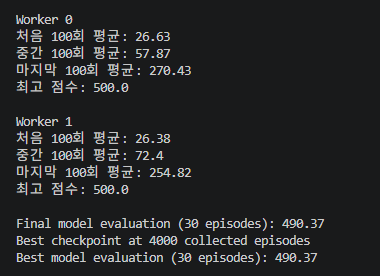
- Worker 0 마지막 100회 평균 : 270.43점
- Worker 1 마지막 100회 평균 : 254.82점
- 최종 모델 평가 평균 : 490.37점
- 최고 성능 모델 평가 평균 : 490.37점


#### 시도1 16.5


#### 시도2 16.3

- 학습 에피소드(Episodes) : 300회 → 1,000회
- 학습률(Learning Rate) : 0.001 → 0.01

#### 시도3 47.4

- N-step : 5 → 20
- 학습률(Learning Rate) : 0.01 → 0.0003
- Optimizer : SGD → Adam

#### 시도4 22.0

- 학습 에피소드(Episodes) : 1,000회 → 1,500회
- N-step : 20 → 10
- 학습률(Learning Rate) : 0.0003 → 0.0001
- Optimizer : Adam 유지
- Worker : 2개 유지

#### 시도5 109.8

- 학습 에피소드(Episodes) : 1,500회 유지
- N-step : 10 → 20
- 학습률(Learning Rate) : 0.0001 → 0.0003
- Optimizer : Worker별 Adam → Shared Adam (Optimizer 상태 공유)
- Worker : 2개 유지
- 멀티프로세스 라이브러리 : multiprocess → torch.multiprocessing (Windows 실행 오류 해결)

___
# **3. PPO**
- 한 번의 경험으로정책을 급격하게 바꾸지 못하도록 함
- 기존 정책을 안정적으로 개선하기 위한 Actor-Critic 계열 알고리즘

```
현재 정책에서 오른쪽 행동 확률이 40%였는데 한 번의 학습으로 95%가 되면, 이전에 수집한 데이터가 새 정책을 잘 대표하지 못할 수 있음(왔다리 갔다리 한다는 뜻)
```

> PPO는 이전 정책과새 정책의 행동 확률을 비교하고, 업데이트가 지나치게 커지지 않도록 목적함수에 제한 둠

### **3-1. 확률 비율**
- 상태 s에서 실제로 선택한 행동 a의 확률 비교

$$r_t(\theta)=\frac{\pi_\theta(a_t\mid s_t)}{\pi_{\theta_{old}}(a_t\mid s_t)}$$

- 분모: 데이터를 수집하던 당시 정책이 그 행동을 선택할 확률
- 분자: 현재 업데이트 중인 정책이 같은 행동을 선택할 확률
- 비율이 1: 확률이 그대로
- 비율이 1.5: 확률이 이전보다 50% 증가
- 비율이 0.7: 확률이 이전보다 30% 감소
    - 예) 예전 정책이 왼쪽을 선택할 확률 0.4, 새 정책은 0.6이라면 r = 0.6 / 0.4 = 1.5

> 행동이 여러 개라도 수집 당시 실제 선택한 행동의 확률을 사용

In [1]:
old_probability = 0.4
new_probability = 0.6
ratio = new_probability / old_probability
print(f"확률 비율: {ratio:.2f}, 이전 대비 변화: {(ratio-1)*100:.0f}%")

확률 비율: 1.50, 이전 대비 변화: 50%


### **3-2. Advantage**
- 실제로 얻은 결과 - Critic이 예측한 값
    - A > 0: 행동을 더 자주 선택하도록 유도
    - A < 0: 행동을 덜 선택하도록 유도
    - A $\approx$ 0: 큰 변화 필요 없음


### 3-3. Clipping
$$L^{CLIP}=\mathbb{E}_t[\min(r_t A_t,\;\operatorname{clip}(r_t,1-\epsilon,1+\epsilon)A_t)]$$



$\epsilon = 0.2$ 라면 비율을 목적함수 계산에서 0.8~1.2로 자름
```
비율 r = 1.5
Advantage A = 2
원래 rA = 3
잘린 비율 = 2.4
최솟값(목적함수) = 2.4
```
일때 이걸 해석하면
- 원래 rA = 3이었지만, clipping으로 인해 2.4로 제한됨
- 따라서 목적함수는 2.4가 됨

In [2]:
import numpy as np

In [3]:
for ratio, advantage in [(1.5, 2), (0.7, 2), (1.5, -2), (0.7, -2)]:
    raw = ratio * advantage
    clipped = np.clip(ratio, 0.8, 1.2) * advantage
    objective = min(raw, clipped)
    print(f"r={ratio:.1f}, A={advantage:+.0f}, 원래={raw:+.2f}, 잘린={clipped:+.2f}, PPO={objective:+.2f}")

# PPO = +2.4 : 좋은 행동 확률을 지나치게 높이는 이득 제한
# PPO= +1.40 : 좋은 행동을 낮추는 손해는 그대로 반영
# PPO= -3.00 : 나쁜 행동 확률을 높이는 손해는 그대로 반영
# PPO = -1.60 : 나쁜 행동 확률을 지나치게 낮추는 이득 제한

# min()을 준 이유 : 정책을 좋은 방향으로 지나치게 바꿔서 얻는 추가 보상을 제한하면서 나쁜 방향으로 바뀌는 경우는 패널티를 유지하기 때문

r=1.5, A=+2, 원래=+3.00, 잘린=+2.40, PPO=+2.40
r=0.7, A=+2, 원래=+1.40, 잘린=+1.60, PPO=+1.40
r=1.5, A=-2, 원래=-3.00, 잘린=-2.40, PPO=-3.00
r=0.7, A=-2, 원래=-1.40, 잘린=-1.60, PPO=-1.60
